This section looks at how the neuron actually learns. Most of the pieces are already in place from earlier sections. Rangeetha derived $\sigma'(z)$ and showed that it collapses once $|z|$ gets large, and Carlos showed that at the Wonderland point $\sigma'(6)$ is only about 0.0025. Here we put those pieces together into a gradient and check it against PyTorch. Then we look at what changes when we vary the loss function, the learning rate and the number of layers.

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Wonderland example from the workshop
x = torch.tensor([1.0, 0.0, 1.0])
w0 = torch.tensor([5.0, 2.0, 4.0])
b0 = -3.0
y = torch.tensor(1.0)

# OR gate data (same as scripts/train_or_perceptron.py), used for the training experiments
X_or = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_or = torch.tensor([0., 1., 1., 1.])

### 1. Following the gradient through the Wonderland neuron

The workshop's loss is $L = (\hat y - y)^2$, with $\hat y = \sigma(z)$ and $z = w \cdot x + b$. The loss doesn't depend on $w_1$ directly. Changing $w_1$ changes $z$, which changes $\hat y$, which changes $L$. The chain rule multiplies those three links together:

$$
\frac{\partial L}{\partial w_j}
= \frac{\partial L}{\partial \hat y}\cdot\frac{\partial \hat y}{\partial z}\cdot\frac{\partial z}{\partial w_j}
= 2(\hat y - y)\cdot \sigma(z)\big(1-\sigma(z)\big)\cdot x_j
$$

The middle factor is the sigmoid derivative from the activation functions section. The cell below works out each factor on its own, multiplies them, and compares the result with what `loss.backward()` stores in `weights.grad`.

In [2]:
weights = w0.clone().requires_grad_(True)
z = torch.dot(weights, x) + b0
y_hat = torch.sigmoid(z)
loss = (y_hat - y) ** 2
loss.backward()

# the same gradient, one factor at a time
dL_dyhat = 2 * (y_hat - y)
dyhat_dz = y_hat * (1 - y_hat)
dz_dw = x
by_hand = (dL_dyhat * dyhat_dz * dz_dw).detach()

print(f"z = {z.item():.1f}   y_hat = {y_hat.item():.6f}   loss = {loss.item():.3e}")
print(f"dL/dy_hat = {dL_dyhat.item():.6f}")
print(f"dy_hat/dz = {dyhat_dz.item():.6f}")
print(f"dz/dw     = {dz_dw.tolist()}")
print()
print("by hand :", by_hand)
print("autograd:", weights.grad)
print("match   :", torch.allclose(by_hand, weights.grad))

with torch.no_grad():
    w_new = weights - 0.1 * weights.grad
print("\nweights after one step with lr = 0.1:", [f"{v:.7f}" for v in w_new.tolist()])

z = 6.0   y_hat = 0.997527   loss = 6.114e-06
dL/dy_hat = -0.004945
dy_hat/dz = 0.002466
dz/dw     = [1.0, 0.0, 1.0]

by hand : tensor([-1.2197e-05, -0.0000e+00, -1.2197e-05])
autograd: tensor([-1.2197e-05, -0.0000e+00, -1.2197e-05])
match   : True

weights after one step with lr = 0.1: ['5.0000014', '2.0000000', '4.0000014']


The two answers match, so autograd is doing exactly the chain rule we wrote down.

Look at the gradient for $w_2$: it is exactly 0, because $x_2 = 0$. An input that is switched off adds nothing to $z$, so its weight can't be blamed for the error and is left alone.

The other two gradients are tiny, about $1.2 \times 10^{-5}$, and one step of gradient descent only moves $w_1$ from 5 to 5.0000014. (The exact change is 0.0000012, but float32 can't store numbers that close to 5 any more precisely, so PyTorch rounds it.) Most of that shrinking comes from the middle factor, $\sigma'(6) \approx 0.0025$. The neuron is already very sure of its answer, so it hardly learns anything from this example.

### 2. Squared error vs cross-entropy

The slow learning above isn't only because the prediction is already nearly right. It comes from pairing squared error with a sigmoid. To see this, we compare it with binary cross-entropy, the loss that is normally used for yes/no outputs:

$$
L_{CE} = -\big[\,y \log \hat y + (1-y)\log(1-\hat y)\,\big]
$$

Its derivative with respect to $\hat y$ is $\dfrac{\hat y - y}{\hat y(1-\hat y)}$. The denominator is exactly $\sigma'(z)$, so it cancels when the chain rule multiplies by $\sigma'(z)$:

$$
\frac{\partial L_{CE}}{\partial w_j} = \frac{\hat y - y}{\hat y(1-\hat y)}\cdot \hat y(1-\hat y)\cdot x_j = (\hat y - y)\,x_j
$$

No sigmoid slope is left in the gradient. The cell below compares the two gradients at the Wonderland point. It then plots how hard each loss pushes on $z$ when the target is 1.

squared error gradient: tensor([-1.2197e-05, -0.0000e+00, -1.2197e-05])
cross-entropy gradient: tensor([-0.0025, -0.0000, -0.0025])
cross-entropy is 203 times larger here

z = -6:  squared error dL/dz = -0.00492   cross-entropy dL/dz = -0.99753
z = +0:  squared error dL/dz = -0.25000   cross-entropy dL/dz = -0.50000
z = +6:  squared error dL/dz = -0.00001   cross-entropy dL/dz = -0.00247


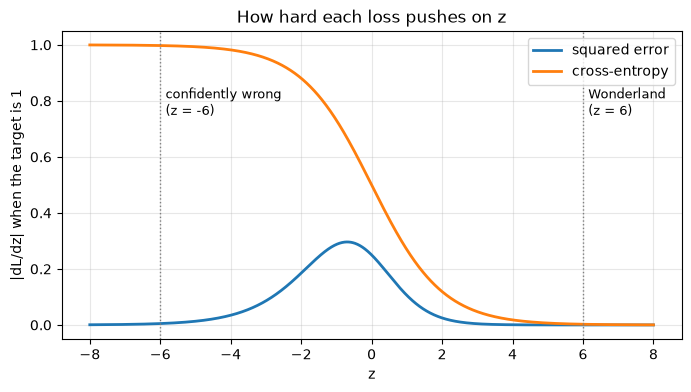

In [3]:
weights = w0.clone().requires_grad_(True)
y_hat = torch.sigmoid(torch.dot(weights, x) + b0)
F.binary_cross_entropy(y_hat, y).backward()

print("squared error gradient:", by_hand)
print("cross-entropy gradient:", weights.grad)
print(f"cross-entropy is {(weights.grad[0] / by_hand[0]).item():.0f} times larger here\n")

# dL/dz for a target of 1, over a range of z
z_vals = torch.linspace(-8, 8, 1601, requires_grad=True)
g_se = torch.autograd.grad(((torch.sigmoid(z_vals) - 1) ** 2).sum(), z_vals)[0]
g_ce = torch.autograd.grad(F.binary_cross_entropy(torch.sigmoid(z_vals), torch.ones(1601), reduction="sum"), z_vals)[0]

for zz in (-6.0, 0.0, 6.0):
    i = torch.argmin((z_vals - zz).abs())
    print(f"z = {zz:+.0f}:  squared error dL/dz = {g_se[i].item():+.5f}   cross-entropy dL/dz = {g_ce[i].item():+.5f}")

plt.figure(figsize=(8, 4))
plt.plot(z_vals.detach(), g_se.abs(), lw=2, label="squared error")
plt.plot(z_vals.detach(), g_ce.abs(), lw=2, label="cross-entropy")
for zz, txt in [(-6, "confidently wrong\n(z = -6)"), (6, "Wonderland\n(z = 6)")]:
    plt.axvline(zz, color="grey", ls=":", lw=1)
    plt.text(zz + 0.15, 0.75, txt, fontsize=9)
plt.xlabel("z")
plt.ylabel("|dL/dz| when the target is 1")
plt.title("How hard each loss pushes on z")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

At $z = 6$, cross-entropy pushes about 200 times harder than squared error. Both numbers are still small, which is fine, because the neuron is right.

The left side of the plot matters more. At $z = -6$ the neuron is confidently **wrong**: it outputs 0.0025 when the answer is 1. Squared error barely reacts ($|dL/dz| \approx 0.005$), because the sigmoid is flat out there and the slope wipes out the gradient. Cross-entropy pushes almost as hard as it can ($\approx 1$). So with squared error, a neuron that starts out badly wrong can take a very long time to recover. That is the main reason classifiers are trained with cross-entropy. The workshop uses squared error because its maths is easier to follow, which is fine for learning the idea.

### 3. Comparing learning rates

The Wonderland example is a single data point that the neuron already gets right, so every learning rate looks the same on it. For this comparison we switch to the OR gate data from `scripts/train_or_perceptron.py`. The neuron, the squared error loss, the update rule and the starting weights (seed 0) are all the same in every run, for 100 epochs. Only the learning rate $\eta$ changes.

    lr | loss ep 1 | loss ep 100 |          weights |    bias | outputs for 00, 01, 10, 11 | correct
----------------------------------------------------------------------------------------------------
  0.01 |    1.8006 |      0.9311 |     [2.03, 0.15] |   -1.52 | [0.179, 0.202, 0.624, 0.659] | 3/4
   0.1 |    1.7757 |      0.1903 |      [2.6, 1.83] |   -0.68 | [0.337, 0.761, 0.872, 0.977] | 4/4
     1 |    1.5343 |      0.0289 |     [4.41, 4.41] |   -1.92 | [0.128, 0.923, 0.924, 0.999] | 4/4
    10 |    1.0605 |      0.0023 |      [7.08, 7.1] |   -3.29 | [0.036, 0.978, 0.978, 1.0] | 4/4
   100 |    1.2250 |      1.0000 |    [26.05, 2.24] |   23.01 | [1.0, 1.0, 1.0, 1.0]       | 3/4

epochs where the loss went UP with lr = 10: [2]


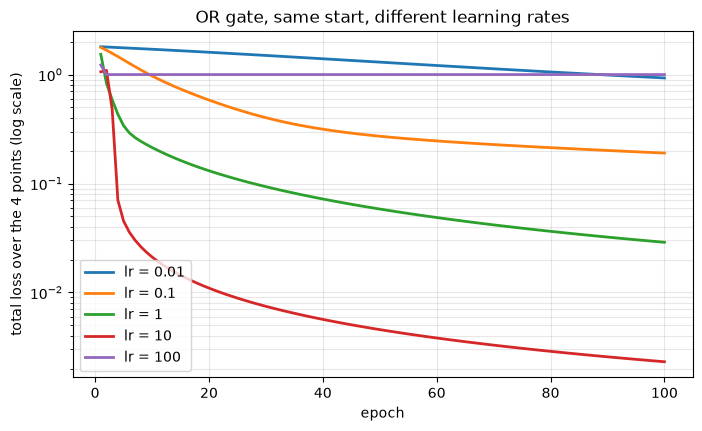

In [4]:
def train_or(lr, epochs=100, seed=0, reset_grads=True):
    torch.manual_seed(seed)
    w = torch.randn(2, requires_grad=True)
    b = torch.randn(1, requires_grad=True)
    history = []
    for epoch in range(epochs):
        total = 0.0
        for x_i, y_i in zip(X_or, y_or):
            loss = (torch.sigmoid(torch.dot(w, x_i) + b) - y_i) ** 2
            total += loss.item()
            loss.backward()
            with torch.no_grad():
                w -= lr * w.grad
                b -= lr * b.grad
            if reset_grads:
                w.grad.zero_()
                b.grad.zero_()
        history.append(total)
    return w.detach(), b.detach(), history

rates = [0.01, 0.1, 1, 10, 100]
runs = {lr: train_or(lr) for lr in rates}

print(f"{'lr':>6} | {'loss ep 1':>9} | {'loss ep 100':>11} | {'weights':>16} | {'bias':>7} | outputs for 00, 01, 10, 11 | correct")
print("-" * 100)
for lr, (w, b, hist) in runs.items():
    out = torch.sigmoid(X_or @ w + b)
    correct = int(((out >= 0.5).float() == y_or).sum())
    print(f"{lr:>6} | {hist[0]:>9.4f} | {hist[-1]:>11.4f} | {str([round(v, 2) for v in w.tolist()]):>16} | {b.item():>7.2f} | "
          f"{str([round(v, 3) for v in out.tolist()]):<26} | {correct}/4")

ups = [e + 2 for e in range(99) if runs[10][2][e + 1] > runs[10][2][e]]   # e + 2 = the later epoch, counting from 1
print("\nepochs where the loss went UP with lr = 10:", ups)

plt.figure(figsize=(8, 4.5))
for lr, (_, _, hist) in runs.items():
    plt.plot(range(1, 101), hist, lw=2, label=f"lr = {lr}")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("total loss over the 4 points (log scale)")
plt.title("OR gate, same start, different learning rates")
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.show()

What we see, from smallest to largest:

- **0.01** is too slow. After 100 epochs the loss has only dropped from 1.80 to 0.93, and (0, 1) is still classified as 0 (output 0.20). It is heading the right way, just in very small steps.
- **0.1** (the workshop's value) gets all four right with a final loss of 0.19. The outputs are still soft, though: (0, 0) sits at 0.34.
- **1** converges much faster, to 0.029, with clear outputs.
- **10** reaches the lowest loss, 0.0023, but the curve isn't smooth. In epoch 2 the loss goes *up*, from 1.06 to 1.09, before falling. That is overshooting: the step is big enough to jump past the bottom of the valley.
- **100** breaks. The first few updates are so large that the bias jumps to about +23. That pushes $z$ deep into the flat top of the sigmoid for every input, so the neuron outputs 1 for everything, including (0, 0). The loss then sits at exactly 1.0 for the rest of training. It can't recover, because (as section 2 showed) the gradient on the flat part of the sigmoid is almost zero.

So a bigger learning rate isn't simply faster. It is faster up to a point. Beyond that, the weights get thrown into a region where learning stops. For this problem anything from 1 to 10 works well.

### 4. What `backward()`, `no_grad()` and `zero_()` actually do

Every training loop in the workshop has the same three lines around the update:

- `loss.backward()` works out the gradient for every tensor created with `requires_grad=True` and **adds** it to that tensor's `.grad`. It adds; it doesn't overwrite.
- `with torch.no_grad():` tells PyTorch that the update is not part of the model, so it shouldn't be recorded for the next backward pass.
- `.grad.zero_()` clears the stored gradient so that the next sample starts from zero.

The next three cells show what happens when each one is missing.

In [5]:
# backward() adds to .grad: same input and same weights, three calls in a row
weights = w0.clone().requires_grad_(True)
for k in range(1, 4):
    loss = (torch.sigmoid(torch.dot(weights, x) + b0) - y) ** 2
    loss.backward()
    print(f"after backward() call {k}: weights.grad = {[f'{v:.4e}' for v in weights.grad.tolist()]}")

after backward() call 1: weights.grad = ['-1.2197e-05', '-0.0000e+00', '-1.2197e-05']
after backward() call 2: weights.grad = ['-2.4394e-05', '-0.0000e+00', '-2.4394e-05']
after backward() call 3: weights.grad = ['-3.6591e-05', '-0.0000e+00', '-3.6591e-05']


Nothing changed between the calls, but the stored gradient goes 1×, 2×, 3×. In a training loop, that means each update would use the sum of every gradient so far instead of the current one. Here is the OR training from section 3 at $\eta = 1$, run with and without `zero_()`:

In [6]:
for reset in (True, False):
    w, b, hist = train_or(lr=1, epochs=30, reset_grads=reset)
    out = torch.sigmoid(X_or @ w + b)
    label = "with zero_()   " if reset else "without zero_()"
    print(f"{label}  loss at epochs 1, 6, 11, ..., 26: {[round(h, 4) for h in hist[::5]]}")
    print(f"{'':<17}weights = {[round(v, 2) for v in w.tolist()]}, bias = {b.item():.2f}, outputs = {[round(v, 3) for v in out.tolist()]}\n")

with zero_()     loss at epochs 1, 6, 11, ..., 26: [1.5343, 0.2923, 0.2016, 0.1554, 0.126, 0.1057]
                 weights = [3.2, 3.04], bias = -1.20, outputs = [0.232, 0.864, 0.881, 0.994]

without zero_()  loss at epochs 1, 6, 11, ..., 26: [1.4839, 0.9994, 1.0, 1.0, 1.0, 1.0]
                 weights = [63.72, 68.29], bias = 59.50, outputs = [1.0, 1.0, 1.0, 1.0]



Without `zero_()` the loss is already 0.9994 by epoch 6 and sits at 1.0 from then on. The weights grow to about 64 and 68 and the bias to about 59, so the neuron says 1 for every input. This is the same failure we got with $\eta = 100$, which makes sense: if gradients keep piling up, every step is bigger than the last. Forgetting `zero_()` behaves like a learning rate that grows on every step.

Finally, here is the update done *without* `torch.no_grad()`:

In [7]:
weights = w0.clone().requires_grad_(True)
loss = (torch.sigmoid(torch.dot(weights, x) + b0) - y) ** 2
loss.backward()
try:
    weights -= 0.1 * weights.grad      # no torch.no_grad() around this
except RuntimeError as err:
    print("RuntimeError:", err)

RuntimeError: a leaf Variable that requires grad is being used in an in-place operation.


PyTorch refuses. `weights` is a tensor that autograd is tracking, and changing it in place would corrupt the record autograd needs for the next backward pass. Inside `torch.no_grad()` the same line is allowed, because PyTorch then treats it as a parameter update rather than part of the forward pass.

### 5. Correcting the slide 5 weight update

The case study's breakdown of slide 5 skips the sigmoid. It treats the raw score $\hat y = 6$ as the output and uses $L = \frac12 (y - \hat y)^2$. That simplification is fine for teaching, but the gradient has the wrong sign. The slide uses $\frac{\partial L}{\partial w_j} = (y - \hat y)\,x_j$. Differentiating properly:

$$
\frac{\partial L}{\partial w_j} = \tfrac12 \cdot 2(y - \hat y)\cdot \frac{\partial (y - \hat y)}{\partial w_j} = (y - \hat y)(-x_j) = (\hat y - y)\,x_j
$$

The minus sign comes from $\hat y$ having a minus in front of it inside the bracket. With $\hat y - y = 5$, the gradients are $[5, 0, 5]$, not $[-5, 0, -5]$. Autograd agrees:

In [8]:
weights = w0.clone().requires_grad_(True)
y_hat_raw = torch.dot(weights, x) + b0          # no sigmoid, as on the slide
loss = 0.5 * (y - y_hat_raw) ** 2
loss.backward()
print("gradient from autograd:", weights.grad.tolist(), "\n")

with torch.no_grad():
    corrected = weights - 0.1 * weights.grad
slide = torch.tensor([5.5, 2.0, 4.5])

for name, w in [("before the update", w0), ("corrected update", corrected), ("slide 5 update", slide)]:
    out = (torch.dot(w, x) + b0).item()
    print(f"{name:<18} w = {[round(v, 2) for v in w.tolist()]}   y_hat = {out:.1f}   error y - y_hat = {1 - out:+.1f}")

gradient from autograd: [5.0, 0.0, 5.0] 

before the update  w = [5.0, 2.0, 4.0]   y_hat = 6.0   error y - y_hat = -5.0
corrected update   w = [4.5, 2.0, 3.5]   y_hat = 5.0   error y - y_hat = -4.0
slide 5 update     w = [5.5, 2.0, 4.5]   y_hat = 7.0   error y - y_hat = -6.0


The corrected weights $[4.5, 2, 3.5]$ bring the output down from 6 to 5, closer to the target of 1. The slide's weights $[5.5, 2, 4.5]$ push it up to 7, further away. That contradicts the slide's own sentence that the new weights "will produce a smaller output". A quick sanity check for any gradient step is that after the update the error should shrink, not grow.

### 6. From gradient descent to backpropagation

**Homework question:** how is this update rule related to backpropagation in multi-layer networks?

Gradient descent is the update itself, $w \leftarrow w - \eta\,\partial L / \partial w$. It doesn't say how to get $\partial L / \partial w$. For a single neuron that was easy, because every weight is one chain-rule step away from the output.

In a network with a hidden layer, a first-layer weight only reaches the loss indirectly: it feeds a hidden neuron, which feeds the output neuron, which feeds the loss. Backpropagation is how those gradients are worked out efficiently: it applies the chain rule one layer at a time, starting at the output and moving backwards. For one hidden layer, with sigmoid everywhere and cross-entropy loss:

$$
\delta^{(2)} = \hat y - y \qquad \text{(error at the output neuron's } z \text{)}
$$
$$
\delta^{(1)} = \big(\delta^{(2)}\, W^{(2)}\big) \odot h\,(1-h) \qquad \text{(error sent back to the hidden layer)}
$$
$$
\frac{\partial L}{\partial W^{(2)}} = \delta^{(2)\top} h, \qquad
\frac{\partial L}{\partial W^{(1)}} = \delta^{(1)\top} x
$$

The hidden layer's error is the output error sent back through the same weights $W^{(2)}$, then scaled by the hidden neurons' own sigmoid slope. Each layer reuses the $\delta$ already computed for the layer after it, so nothing is calculated twice. Once all the gradients are known, every weight is updated with the same gradient descent rule as before. In short, backprop finds the gradients and gradient descent uses them.

To try this on a problem one neuron can't solve, we train a 2-2-1 network on XOR, which Davisen's section proved is impossible for a single perceptron. First we check one backward pass by hand against autograd.

In [9]:
X_xor = X_or.clone()
y_xor = torch.tensor([[0.], [1.], [1.], [0.]])

def init_net(seed):
    torch.manual_seed(seed)
    W1 = torch.randn(2, 2, requires_grad=True)    # hidden layer: 2 neurons, 2 inputs each
    b1 = torch.zeros(2, requires_grad=True)
    W2 = torch.randn(1, 2, requires_grad=True)    # output neuron: 2 inputs (the hidden neurons)
    b2 = torch.zeros(1, requires_grad=True)
    return [W1, b1, W2, b2]

def forward(params, X):
    W1, b1, W2, b2 = params
    h = torch.sigmoid(X @ W1.T + b1)
    out = torch.sigmoid(h @ W2.T + b2)
    return h, out

params = init_net(seed=2)
h, out = forward(params, X_xor)
F.binary_cross_entropy(out, y_xor).backward()

with torch.no_grad():
    W1, b1, W2, b2 = params
    n = len(X_xor)
    d2 = (out - y_xor) / n             # output error (divided by n because the loss is averaged over the 4 rows)
    d1 = (d2 @ W2) * h * (1 - h)       # error sent back to the hidden layer
    by_hand = [d1.T @ X_xor, d1.sum(0), d2.T @ h, d2.sum(0)]

for name, g, p in zip(["W1", "b1", "W2", "b2"], by_hand, params):
    print(f"{name}: by hand = {[round(v, 5) for v in g.flatten().tolist()]}   matches autograd: {torch.allclose(g, p.grad, atol=1e-7)}")

W1: by hand = [0.01376, 0.01247, 0.00168, -0.00238]   matches autograd: True
b1: by hand = [0.02259, -0.00831]   matches autograd: True
W2: by hand = [0.04354, 0.02864]   matches autograd: True
b2: by hand = [0.08243]   matches autograd: True


The hand-written backward pass matches autograd for all four parameter tensors. Now we train with autograd, using the same loop as before, and try six different random starting points.

In [10]:
def train_xor(seed, lr=1.0, epochs=5000):
    params = init_net(seed)
    for epoch in range(epochs):
        _, out = forward(params, X_xor)
        loss = F.binary_cross_entropy(out, y_xor)
        loss.backward()
        with torch.no_grad():
            for p in params:
                p -= lr * p.grad
                p.grad.zero_()
    return params, loss.item()

params, final_loss = train_xor(seed=2)
h, out = forward(params, X_xor)
print(f"seed 2, final loss = {final_loss:.4f}")
for x_i, h_i, o_i in zip(X_xor.int().tolist(), h.detach(), out.detach()):
    print(f"  x = {x_i}   hidden = ({h_i[0]:.2f}, {h_i[1]:.2f})   output = {o_i.item():.3f}   predicted = {int(o_i.item() >= 0.5)}")

print("\nsix random starts:")
for seed in range(6):
    p, l = train_xor(seed)
    _, o = forward(p, X_xor)
    solved = bool(((o >= 0.5).float() == y_xor).all())
    print(f"  seed {seed}: loss = {l:.4f}   outputs = {[round(v, 3) for v in o.detach().flatten().tolist()]}   solved XOR: {solved}")

seed 2, final loss = 0.0021
  x = [0, 0]   hidden = (1.00, 0.96)   output = 0.002   predicted = 0
  x = [0, 1]   hidden = (0.95, 0.01)   output = 0.998   predicted = 1
  x = [1, 0]   hidden = (0.95, 0.01)   output = 0.998   predicted = 1
  x = [1, 1]   hidden = (0.04, 0.00)   output = 0.003   predicted = 0

six random starts:


  seed 0: loss = 0.3480   outputs = [0.001, 0.998, 0.5, 0.501]   solved XOR: False


  seed 1: loss = 0.0070   outputs = [0.006, 0.992, 0.992, 0.005]   solved XOR: True


  seed 2: loss = 0.0021   outputs = [0.002, 0.998, 0.998, 0.003]   solved XOR: True


  seed 3: loss = 0.0021   outputs = [0.002, 0.998, 0.998, 0.002]   solved XOR: True


  seed 4: loss = 0.3480   outputs = [0.002, 0.999, 0.499, 0.501]   solved XOR: False


  seed 5: loss = 0.3478   outputs = [0.001, 0.999, 0.499, 0.501]   solved XOR: False


With seed 2 the network learns XOR, and every output is within 0.003 of its target. The hidden columns show how it did it. Hidden neuron 1 is off only for $[1, 1]$, so it behaves like **NAND**. Hidden neuron 2 is on only for $[0, 0]$, so it behaves like **NOR**. The output fires when the first is on and the second is off, which is NAND AND (NOT NOR) = NAND AND OR. That is the same decomposition Davisen built by hand, except here the network found it on its own from random weights.

The six random starts show the catch. Three of them (seeds 0, 4 and 5) stop at a loss of about 0.348 and leave two of the inputs sitting on the fence at 0.5. The gradient there is close to zero, but the answer is still wrong. This is a **local minimum**. Gradient descent only ever walks downhill from wherever it starts, so the starting weights matter. This never happened with the single neuron, whose loss surface has only one valley. With a hidden layer there can be several. In practice it is handled with more hidden neurons than the bare minimum, or by simply restarting from different random weights.

### 7. The training script and what the debugger shows

We added `--lr` and `--epochs` options to `scripts/train_or_perceptron.py`, plus a printout of what the trained neuron predicts. That printout exposed something the original output hides. With the default settings ($\eta = 0.1$, 20 epochs) the loss falls to 0.58, but the "trained" neuron still gets (0, 1) wrong:

| command | (0, 0) | (0, 1) | (1, 0) | (1, 1) |
|---|---|---|---|---|
| `python scripts/train_or_perceptron.py` | 0.249 | **0.356 (wrong)** | 0.759 | 0.839 |
| `python scripts/train_or_perceptron.py --epochs 200` | 0.272 | 0.822 | 0.871 | 0.988 |
| `python scripts/train_or_perceptron.py --lr 1` | 0.277 | 0.837 | 0.875 | 0.989 |

Ten times the epochs and ten times the learning rate end up in almost the same place. While the gradients are small and fairly steady, ten small steps cover about the same ground as one step ten times bigger. (Section 3 showed where that stops being true.)

We ran the script in the VS Code debugger with a breakpoint on `loss.backward()` and stepped through the first two samples:

- Before the first call, `weights.grad` is `None`. PyTorch only creates the `.grad` tensor the first time `backward()` runs.
- The first sample is $x = [0, 0]$ with target 0. So $z$ is just the bias, $-2.179$, giving $\hat y = 0.102$ and a loss of 0.0103.
- After `backward()`, `weights.grad` is `[0, 0]` and `bias.grad` is 0.0186. With both inputs at 0, only the bias gets any blame, the same thing we saw with $w_2$ in section 1.
- After the update the bias moves from $-2.1788$ to $-2.1806$, and the weights don't move at all.
- On the second sample, $x = [0, 1]$, only the second weight and the bias get gradients (both $-0.132$), because $x_1 = 0$.

### Talking points

1. **A gradient is a product of local slopes, and the sigmoid's slope is usually the bottleneck.** At the Wonderland point $\sigma'(6) \approx 0.0025$, so one update moves $w_1$ by about one millionth. With squared error, a neuron that is confidently *wrong* barely learns either. Cross-entropy cancels the sigmoid slope, so it learns hardest exactly when it is most wrong.
2. **The learning rate isn't a speed dial.** On the OR gate, 0.01 was too slow, 1 to 10 worked well, and 100 threw the weights into the flat part of the sigmoid, where learning stopped for good. Forgetting `grad.zero_()` caused exactly the same failure, because gradients that pile up act like an ever-growing learning rate.
3. **Backpropagation finds the gradients and gradient descent uses them.** Backprop is the chain rule applied one layer at a time, reusing each layer's error. Together they learned XOR, which no single perceptron can. But they only walk downhill from where they start, and three of our six random starts got stuck in a local minimum.